# Bulk Hi-C to 3-D: MDS and IGM population deconvolution

A bulk Hi-C map averages millions of cells.  This tutorial turns one into 3-D structures in two ways:
a single **consensus structure** by multidimensional scaling (`uchrom.recon.bulk.mds`: contacts →
distances → SMACOF, PyTorch on CPU / CUDA / Apple MPS), and a **population of structures** whose
contacts together reproduce the map — IGM's deconvolution (`uchrom.recon.bulk.deconv.deconvolve(...,
method="igm")` on the native engine `uchrom_recon`).  Both are checked against the input and against
imaging data the methods never saw.

**Data**: Rao et al. 2014, *Cell* 159:1665 (in situ Hi-C, IMR90, GEO GSE63525), chromosome 21 at 5 kb,
hg19 — `example-data/rao2014_imr90/IMR90_chr21_5kb_hg19.cool` (3.8 MB, in the repository); for the
independent check, Bintu et al. 2018, *Science* 362:eaau1783 (chromatin tracing of IMR90
chr21:20.0–21.95 Mb hg19, 30 kb segments) — `example-data/IMR90_chr21-18-20Mb.csv` (2 MB, GitHub; fetched
on first use).  **Runtime**: about 3 min on a laptop CPU (18 cores), most of it the IGM population
(50 structures).

In [1]:
import contextlib
import io
import subprocess
import sys
import time
import urllib.request
import warnings
from pathlib import Path

import cooler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.spatial.distance import pdist, squareform
from scipy.stats import pearsonr, spearmanr

from chromdata import ChromData
from uchrom.io import read_bintu_tracing
from uchrom.recon.bulk.deconv import deconvolve
from uchrom.recon.bulk.deconv.igm import contact_probabilities, population_array
from uchrom.recon.bulk.deconv.preprocess import IGMPreprocessParams, preprocess_hic
from uchrom.recon.bulk.mds import apply_transform, procrustes_alignment, run_mds

plt.rcParams["figure.dpi"] = 90
warnings.filterwarnings("ignore", message="linalg.eigh: matrix too large")   # MPS falls back to the CPU for the eigen-decomposition


def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "example-data" / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the U-Chrom repository")


REPO = find_repo_root(); DATA = REPO / "example-data"; OUT = REPO / "tutorials" / "_out"; OUT.mkdir(exist_ok=True)
OUT = OUT / "bulk_reconstruction"; OUT.mkdir(exist_ok=True)

COOL = DATA / "rao2014_imr90" / "IMR90_chr21_5kb_hg19.cool"     # Rao 2014 IMR90 chr21, 5 kb, raw counts, hg19
BINTU = DATA / "IMR90_chr21-18-20Mb.csv"                        # Bintu 2018 IMR90 tracing (catalogued, GitHub raw)
if not BINTU.exists():
    print(f"downloading {BINTU.relative_to(REPO)} (2 MB) from github.com/BogdanBintu/ChromatinImaging")
    urllib.request.urlretrieve("https://raw.githubusercontent.com/BogdanBintu/ChromatinImaging/master/Data/"
                               "IMR90_chr21-18-20Mb.csv", BINTU)
clr5 = cooler.Cooler(str(COOL))
print(f"{COOL.relative_to(REPO)}: {clr5.info['nbins']:,} bins x {clr5.binsize // 1000} kb, "
      f"{clr5.info['sum']:,} contacts ({clr5.info['genome-assembly']})")

example-data/rao2014_imr90/IMR90_chr21_5kb_hg19.cool: 9,626 bins x 5 kb, 10,266,877 contacts (hg19)


## The input map

Whole-chromosome MDS works on a dense matrix, so we sum the 5 kb map into 100 kb bins
(`cooler.coarsen_cooler`) and balance it (ICE, `cooler.balance_cooler`).  The first ~14 Mb of chr21
(the acrocentric short arm) have no mappable reads.

100 kb: 482 bins, 327 with contacts


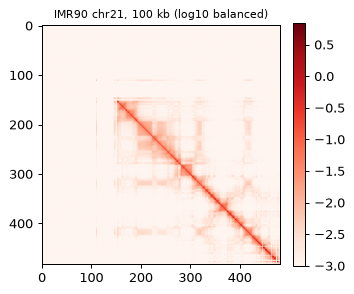

In [2]:
def coarsened(res):
    path = OUT / f"IMR90_chr21_{res // 1000}kb.cool"
    if not path.exists():
        cooler.coarsen_cooler(str(COOL), str(path), factor=res // clr5.binsize, chunksize=10_000_000)
        cooler.balance_cooler(cooler.Cooler(str(path)), store=True)
    clr = cooler.Cooler(str(path))
    return path, clr.bins().fetch("chr21")[["chrom", "start", "end"]].reset_index(drop=True), \
        np.nan_to_num(clr.matrix(balance=True).fetch("chr21"))


COOL100, bins100, M100 = coarsened(100_000)
print(f"100 kb: {len(bins100)} bins, {(M100.sum(1) > 0).sum()} with contacts")
fig, ax = plt.subplots(figsize=(4, 3.6))
im = ax.imshow(np.log10(M100 + 1e-4), cmap="Reds", vmin=-3)
ax.set_title("IMR90 chr21, 100 kb (log10 balanced)", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()

## A consensus structure by MDS

`run_mds` drops bins without contacts, smooths the map with a distance-decay prior (`weight`, the share
of the expected count mixed into every entry), converts contacts to distances `d = c^(-1/alpha)`, and
minimises the stress with SMACOF from a classical-MDS start (`method="adam"` uses autograd + Adam on
the same stress instead).  It returns the coordinates of the kept bins and the mask.  The units are
arbitrary (mean target distance 1).

In [3]:
t0 = time.time()
X100, keep100 = run_mds(torch.from_numpy(M100), alpha=4.0, weight=0.05, device="cpu", n_iter=1000)
t_mds = time.time() - t0
kept = bins100[keep100].reset_index(drop=True)
mds = ChromData.from_dataframe(kept.assign(x=X100[:, 0], y=X100[:, 1], z=X100[:, 2]), cell_id="IMR90_bulk",
                               uns={"xyz_unit": "arbitrary (MDS)", "genome_assembly": "hg19"})
mds.write(OUT / "IMR90_chr21_100kb_mds.chromdata.zarr")
print(f"SMACOF on the CPU: {t_mds:.2f} s -> {mds}")

Processing on device: cpu (dtype: torch.float64)
  Removed 155 zero-contact bins (327/482 kept)


SMACOF on the CPU: 0.12 s -> ChromData: n_spots=327, n_traces=1, n_cells=1, n_bins=327
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  uns:     ['xyz_unit', 'genome_assembly']


## Quality checks

No single number says that a consensus structure is right.  We use four:

1. **Input–output correlation** — Spearman correlation between the contact frequency and `1 / d` over
   the observed pairs: does the structure reproduce the map?
2. The same **after removing the distance decay** (each value divided by the mean at its genomic
   separation): does it reproduce more than the polymer trend — domains, compartments?
3. **Solver agreement** — SMACOF vs Adam, Pearson r of pairwise distances after Procrustes
   superposition.
4. **Imaging** — the Bintu 2018 tracing of chr21:20.0–21.95 Mb in IMR90 cells, which MDS never saw:
   correlation between model distances and the median distances of 1,277 imaged chromosomes.

In [4]:
def observed_over_expected(A):
    # divide every off-diagonal entry by the mean of its diagonal (genomic separation)
    n = len(A); out = np.full_like(A, np.nan, dtype=float)
    for k in range(1, n):
        i = np.arange(n - k); v = A[i, i + k]; pos = v > 0
        if pos.any():
            out[i, i + k] = out[i + k, i] = np.where(pos, v / v[pos].mean(), np.nan)
    return out


def io_checks(X, M):
    D = squareform(pdist(X)); iu = np.triu_indices(len(X), 1)
    ok = M[iu] > 0
    rho = spearmanr(M[iu][ok], 1 / D[iu][ok])[0]
    Moe, Doe = observed_over_expected(M), observed_over_expected(D)
    ok2 = np.isfinite(Moe[iu]) & np.isfinite(Doe[iu])
    rho_oe = spearmanr(Moe[iu][ok2], 1 / Doe[iu][ok2])[0]
    return rho, rho_oe


fish = read_bintu_tracing(str(BINTU), chrom="chr21", start_bp=20_000_032, resolution_bp=30_000)
fish.uns["genome_assembly"] = "hg19"       # segment 1 at hg19 chr21:20,000,032 (= hg38 18,627,714)
fl = fish.spots_with_loci()
print(f"Bintu 2018: {fish.n_traces:,} imaged chromosomes x {fish.n_bins} segments, "
      f"chr21:{fl['start'].min():,}-{fl['end'].max():,} (hg19)")


def fish_on_bins(bins):
    # median FISH distance (nm) between model bins: segments averaged per bin and trace, then median over traces
    ends = bins["end"].to_numpy()
    b = np.searchsorted(ends, ((fl["start"] + fl["end"]) // 2).to_numpy(), side="right")
    cen = pd.DataFrame(fish.coords, columns=list("xyz")).assign(trace=fl["trace_id"].to_numpy(), bin=b) \
        .groupby(["trace", "bin"])[list("xyz")].mean()
    ub = np.sort(cen.index.get_level_values("bin").unique())
    C = np.full((cen.index.get_level_values("trace").nunique(), len(ub), 3), np.nan)
    C[pd.factorize(cen.index.get_level_values("trace"))[0], np.searchsorted(ub, cen.index.get_level_values("bin"))] = cen.to_numpy()
    with warnings.catch_warnings():                 # all-NaN pairs (bins not imaged in a trace)
        warnings.simplefilter("ignore", RuntimeWarning)
        D = np.nanmedian(np.linalg.norm(C[:, :, None] - C[:, None], axis=-1), axis=0)
    return ub, D, C


def fish_r(X, bins):
    ub, Df, _ = fish_on_bins(bins)
    Dm = squareform(pdist(X[ub])); iu = np.triu_indices(len(ub), 1)
    return pearsonr(Df[iu], Dm[iu])[0], len(ub)


rho, rho_oe = io_checks(X100, M100[keep100][:, keep100])
r_fish, n_fish = fish_r(X100, kept)
t0 = time.time()
with contextlib.redirect_stdout(io.StringIO()):          # run_mds reports the device and the dropped bins
    X_adam, _ = run_mds(torch.from_numpy(M100), alpha=4.0, weight=0.05, device="cpu", n_iter=1000, method="adam")
t_adam = time.time() - t0
R, t, s = procrustes_alignment(X_adam, X100)
r_solvers = pearsonr(pdist(apply_transform(X_adam, R, t, s)), pdist(X100))[0]
print(f"1. input-output Spearman (contact vs 1/d):         {rho:.3f}")
print(f"2. the same on observed/expected:                  {rho_oe:.3f}")
print(f"3. SMACOF ({t_mds:.2f} s) vs Adam ({t_adam:.2f} s), distance r: {r_solvers:.3f}")
print(f"4. vs Bintu FISH median distances ({n_fish} bins):  Pearson {r_fish:.3f}")

Bintu 2018: 1,277 imaged chromosomes x 65 segments, chr21:20,000,032-21,950,032 (hg19)


1. input-output Spearman (contact vs 1/d):         0.924
2. the same on observed/expected:                  0.803
3. SMACOF (0.12 s) vs Adam (1.15 s), distance r: 0.995
4. vs Bintu FISH median distances (20 bins):  Pearson 0.627


### Resolution and device

Finer bins mean more, sparser bins: the map is noisier, MDS has more to place, and the agreement with
the input drops.  `device="auto"` takes CUDA or Apple MPS (float32) when available.

In [5]:
rows = []
for res in (250_000, 100_000, 50_000, 25_000):
    _, b, M = coarsened(res)
    for dev in ("cpu", "auto"):
        t0 = time.time()
        with contextlib.redirect_stdout(io.StringIO()):
            X, keep = run_mds(torch.from_numpy(M), alpha=4.0, weight=0.05, device=dev, n_iter=1000)
        dt = time.time() - t0
        rho, rho_oe = io_checks(X, M[keep][:, keep])
        rows.append({"resolution_kb": res // 1000, "device": dev, "bins_kept": int(keep.sum()), "seconds": dt,
                     "io_spearman": rho, "io_spearman_oe": rho_oe,
                     "fish_pearson": fish_r(X, b[keep].reset_index(drop=True))[0]})
sweep = pd.DataFrame(rows)
sweep.round(3)

,resolution_kb,device,bins_kept,seconds,io_spearman,io_spearman_oe,fish_pearson
0,250,cpu,127,0.046,0.944,0.836,0.861
1,250,auto,127,0.341,0.944,0.836,0.861
2,100,cpu,327,0.114,0.924,0.803,0.627
3,100,auto,327,0.254,0.924,0.803,0.627
4,50,cpu,660,0.474,0.867,0.722,0.578
5,50,auto,660,0.474,0.867,0.722,0.578
6,25,cpu,1321,0.864,0.738,0.568,0.641
7,25,auto,1321,1.054,0.738,0.568,0.641


At 100–250 kb the consensus structure reproduces the map, also beyond the distance decay (the O/E
column); finer bins are sparser and the agreement drops.  The imaged distances are matched only
moderately (r ≈ 0.6 at 25–100 kb; the higher value at 250 kb rests on 8 bins and mostly reflects the
distance decay): one consensus structure averages over very different single-cell conformations.
`device="auto"` (Apple MPS here) gives the same structures; at these sizes (at most 1,321 bins, about
a second) the device hardly matters — a GPU pays off for matrices of many thousands of bins.

### Command line

`python -m uchrom.recon.bulk.mds` does the same from a `.hic`, `.mcool` or `.cool` file (balanced
matrix; `--partitioned` for TAD-wise divide and conquer at high resolution, `--inter` for a whole-genome
structure with inter-chromosomal contacts):

In [6]:
out = OUT / "IMR90_chr21_100kb_mds_cli.chromdata.zarr"
cmd = [sys.executable, "-m", "uchrom.recon.bulk.mds", str(COOL100.relative_to(REPO)), str(out.relative_to(REPO)),
       "--resolution=100000", "--chrom=chr21", "--device=cpu"]
run = subprocess.run(cmd, cwd=REPO, capture_output=True, text=True)
print("$ python", " ".join(cmd[1:]))
print(f"exit code {run.returncode}; {ChromData.read(out).n_spots} bins written to {out.relative_to(REPO)}")

$ python -m uchrom.recon.bulk.mds tutorials/_out/bulk_reconstruction/IMR90_chr21_100kb.cool tutorials/_out/bulk_reconstruction/IMR90_chr21_100kb_mds_cli.chromdata.zarr --resolution=100000 --chrom=chr21 --device=cpu
exit code 0; 327 bins written to tutorials/_out/bulk_reconstruction/IMR90_chr21_100kb_mds_cli.chromdata.zarr


## A population of structures: IGM

IGM (Boninsegna et al. 2022, *Nat Methods* 19:938; its predecessor PGS: Tjong et al. 2016, *PNAS*
113:E1663) fits a population of *S* diploid structures to the map.  The map is first turned into
**contact probabilities**; then IGM alternates an assignment step (A: given the current population,
decide which structures should carry each contact so that the fraction of structures in contact
matches its probability) and a modelling step (M: anneal and minimise every structure under its
contacts, chain connectivity, excluded volume and the nuclear envelope), lowering a probability
threshold σ from 1 to 0.01 so that rarer contacts enter step by step.  The native engine runs both
steps (protocol `"igm"`, multi-core CPU or GPU); coordinates are in nm.

### Hi-C → contact probabilities

`preprocess_hic` implements the preprocessing of the IGM paper (Supplementary section 6): coverage
filter and Knight–Ruiz balancing at 20 kb, then 200 kb probabilities from the top 10 % of the fine
values of every block, with the scale chosen so that a bin has 24 contacts on average; neighbours get
probability 1.

0.6 s: 241 bins of 200 kb, 62 masked (no valid 20 kb bin); f_max = 3.39e-03, mean contacts per bin 24.0
pairs with p >= sigma: {'1.0': 521, '0.2': 2503, '0.1': 5575, '0.05': 9934, '0.02': 11913, '0.01': 12180}


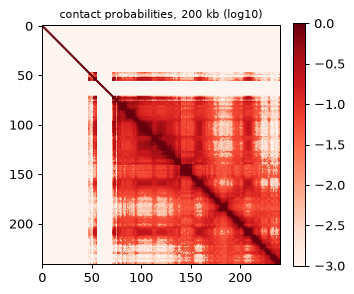

In [7]:
t0 = time.time()
prob = preprocess_hic(COOL, chroms=["chr21"], params=IGMPreprocessParams())   # 20 kb fine, 200 kb coarse
P = prob.probabilities.toarray()
pv = prob.provenance
print(f"{time.time() - t0:.1f} s: {pv['n_coarse']} bins of 200 kb, {pv['n_coarse_masked']} masked (no valid 20 kb bin); "
      f"f_max = {pv['fmax']:.2e}, mean contacts per bin {pv['average_contacts_final']:.1f}")
print("pairs with p >= sigma:", {s: v["intra"] for s, v in pv["pairs_at_or_above"].items()})
fig, ax = plt.subplots(figsize=(4, 3.6))
im = ax.imshow(np.log10(P + 1e-4), cmap="Reds", vmin=-3, vmax=0)
ax.set_title("contact probabilities, 200 kb (log10)", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()

### Running the population

We model chr21 alone — both copies (`ploidy="diploid"`, the default) — inside a full-size nucleus
(sphere of 5 µm radius).  `occupancy_scope` sets the bead size: with the diploid genome size
(2 × 3.1 Gb) the beads get the size they have in a whole-genome model at 20 % occupancy (IGM's
default), instead of chr21 alone filling 20 % of the nucleus.  IGM's defaults are 10,000 structures
(the paper: 1,000 at 200 kb); here **50 structures on the CPU** keep the run to a few minutes — a
small population, enough for the checks below.  Use `device="gpu"` and
thousands of structures for real work (`out="pop.chromdata.zarr"` streams a large population to disk).

In [8]:
N_STRUCTURES = 50
GENOME_BP = 2 * 3.1e9                     # diploid human genome: beads sized as in a whole-genome model
t0 = time.time()
rounds = []
pop = deconvolve(prob.probabilities, bins=prob.bins, method="igm", n_structures=N_STRUCTURES, device="cpu",
                 seed=1, occupancy_scope=GENOME_BP, progress=rounds.append)
t_igm = time.time() - t0
pop.write(OUT / "IMR90_chr21_igm.chromdata.zarr")
print(f"IGM: {N_STRUCTURES} structures in {t_igm / 60:.1f} min on the CPU ({pop.uns['deconv']['engine']})")
pop

IGM: 50 structures in 2.3 min on the CPU (cpu[18 threads])


ChromData: n_spots=24100, n_traces=100, n_cells=50, n_bins=241
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  cells:   ['violation_score', 'n_hic_restraints', 'hic_imposed', 'hic_violated', 'poly_imposed', 'poly_violated', 'env_imposed', 'env_violated', 'hic_inter_imposed', 'hic_inter_violated', 'energy', 'cg_iterations'] (50 cells)
  tracks (bins):  ['radius_nm', 'input_prob_rowsum']
  traces:  ['cell_id', 'chrom', 'copy'] (100 traces)
  results: ['deconv.igm']
  uns:     ['deconv', 'xyz_unit']

The population is a `ChromData` like any other: one **cell** per structure (`s00000` …, with its
violation statistics in `cells`), one **trace** per chromosome copy (`s00000:chr21:0`, `traces` has
`chrom` / `copy`), one spot per bead; `bin_tracks["radius_nm"]` holds the bead radii and
`uns["deconv"]` the parameters and the per-round log.

In [9]:
log = pd.DataFrame([{k: r[k] for k in ("round", "intra_sigma", "iteration", "n_pairs_restrained",
                                        "violation_score", "seconds_mstep")} for r in pop.uns["deconv"]["rounds"]])
print(f"bead radius {np.nanmedian(pop.bin_tracks['radius_nm']):.0f} nm; "
      f"structures with violations: {(pop.cells['violation_score'] > 0).sum()} of {len(pop.cells)} "
      f"(max violation score {pop.cells['violation_score'].max():.4f})")
log.round(4)

bead radius 93 nm; structures with violations: 19 of 50 (max violation score 0.0015)


,round,intra_sigma,iteration,n_pairs_restrained,violation_score,seconds_mstep
0,1,1.00,0,521,0.0000,11.8345
1,2,0.20,0,2499,0.0004,19.7376
2,3,0.10,0,5282,0.0005,22.4091
3,4,0.05,0,8664,0.0007,24.9958
4,5,0.02,0,9004,0.0004,23.5895
5,6,0.01,0,8611,0.0002,24.2855


### Checks

1. **Fit**: the population's contact probabilities (`contact_probabilities`: the fraction of structures
   and copies in which two beads touch, IGM's own definition) against the input probabilities.
2. **Imaging, never used by IGM**: distances in nm against the Bintu 2018 medians in the same region —
   both the pattern (Pearson) and the absolute scale (model / FISH).
3. **Cell-to-cell variability**: a population should spread like single cells do.  Compare the
   distribution of one distance across structures with the same distance across imaged chromosomes.

1. fit: Pearson 0.989 over 15,931 pairs; mean |p_model - p_input| 0.024 for p >= 0.01
2. vs FISH (10 bins of 200 kb): Pearson 0.864, median ratio model / FISH 0.80
3. 20.0 Mb <-> 21.8 Mb: coefficient of variation FISH 0.68, IGM 0.28


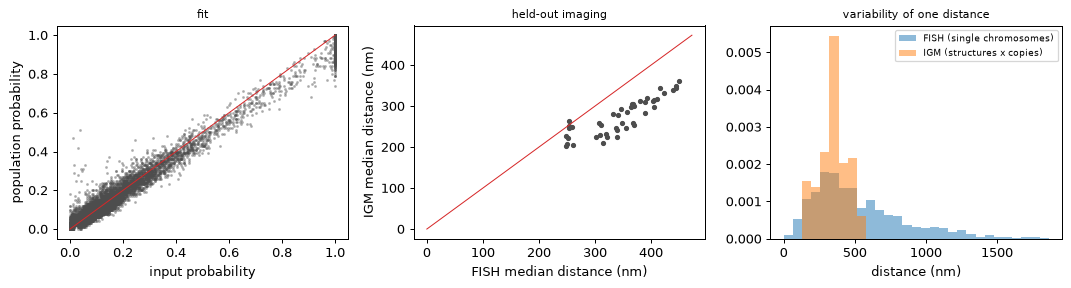

In [10]:
Pm = contact_probabilities(pop)
valid = ~prob.bins["masked"].to_numpy()
iu = np.triu_indices(len(P), 1)
m = valid[iu[0]] & valid[iu[1]]
x, y = P[iu][m], Pm[iu][m]
print(f"1. fit: Pearson {pearsonr(x, y)[0]:.3f} over {m.sum():,} pairs; "
      f"mean |p_model - p_input| {np.abs(x - y)[x >= 0.01].mean():.3f} for p >= 0.01")

X, pbins, cell_ids = population_array(pop)                 # (structures, bins, copies, 3), nm
ub, Df, C = fish_on_bins(pop.bins)
Y = X[:, ub]
Dpop = np.concatenate([np.linalg.norm(Y[:, :, k, None] - Y[:, None, :, k], axis=-1) for k in range(Y.shape[2])])
Dm = np.nanmedian(Dpop, axis=0)
iu2 = np.triu_indices(len(ub), 1)
print(f"2. vs FISH ({len(ub)} bins of 200 kb): Pearson {pearsonr(Df[iu2], Dm[iu2])[0]:.3f}, "
      f"median ratio model / FISH {np.median(Dm[iu2] / Df[iu2]):.2f}")

i, j = 0, len(ub) - 1
d_fish = np.linalg.norm(C[:, i] - C[:, j], axis=-1); d_fish = d_fish[np.isfinite(d_fish)]
d_pop = Dpop[:, i, j]
print(f"3. {pop.bins.loc[ub[i], 'start'] / 1e6:.1f} Mb <-> {pop.bins.loc[ub[j], 'start'] / 1e6:.1f} Mb: "
      f"coefficient of variation FISH {d_fish.std() / d_fish.mean():.2f}, IGM {d_pop.std() / d_pop.mean():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
ax[0].scatter(x, y, s=2, alpha=0.3, color="0.3"); ax[0].plot([0, 1], [0, 1], "C3", lw=0.8)
ax[0].set_xlabel("input probability"); ax[0].set_ylabel("population probability"); ax[0].set_title("fit", fontsize=9)
ax[1].scatter(Df[iu2], Dm[iu2], s=10, color="0.3")
lim = [0, max(Df[iu2].max(), Dm[iu2].max()) * 1.05]; ax[1].plot(lim, lim, "C3", lw=0.8)
ax[1].set_xlabel("FISH median distance (nm)"); ax[1].set_ylabel("IGM median distance (nm)")
ax[1].set_title("held-out imaging", fontsize=9)
bins_h = np.linspace(0, np.percentile(np.r_[d_fish, d_pop], 99), 30)
ax[2].hist(d_fish, bins=bins_h, density=True, alpha=0.5, label="FISH (single chromosomes)")
ax[2].hist(d_pop, bins=bins_h, density=True, alpha=0.5, label="IGM (structures x copies)")
ax[2].set_xlabel("distance (nm)"); ax[2].legend(fontsize=7); ax[2].set_title("variability of one distance", fontsize=9)
fig.tight_layout()

The population reproduces the input probabilities closely — that is what IGM optimises — and, without
having seen the imaging, the pattern of the imaged distances and their absolute scale to within about
20 % (the model is somewhat more compact; its scale comes only from the nucleus size, the occupancy and
the contact definition).  It is less variable than the imaged chromosomes: part of the FISH spread is
measurement noise (localisation error, missed segments), part is cell-to-cell heterogeneity that
50 structures fitted to a 200 kb map do not reach.  Three of the structures — each holds two copies of
chr21, often in separate territories:

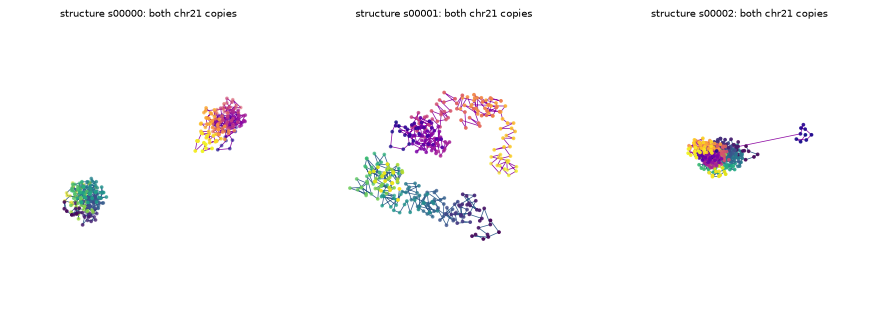

In [11]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers the 3-D projection)

fig = plt.figure(figsize=(10, 3.4))
for k in range(3):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    for cp, cmap in ((0, "viridis"), (1, "plasma")):
        Z = X[k, valid, cp]
        ax.plot(*Z.T, lw=0.6, color=plt.get_cmap(cmap)(0.3))
        ax.scatter(*Z.T, c=np.arange(len(Z)), cmap=cmap, s=4)
    ax.set_title(f"structure {cell_ids[k]}: both chr21 copies", fontsize=8); ax.set_axis_off()
fig.tight_layout()

## Notes

* **What the numbers mean**: the MDS checks use the map the structure was computed from (1–3) and one
  held-out imaging region (4).  The IGM fit is the quantity IGM optimises; the FISH comparison is
  independent of it — including the absolute scale, which comes only from the nucleus size and the
  bead packing.
* **Population size**: IGM's statistics converge with thousands of structures (the IGM paper: 1,000 at
  200 kb, whole genome).  The native engine runs those on a GPU (`device="gpu"`) or a multi-core CPU;
  `benchmarks/bulk/` compares it with the original IGM.
* **Whole genome**: pass all chromosomes to `preprocess_hic` (and a `.mcool` / `.hic`); then
  inter-chromosomal probabilities enter the A-step as well, and `occupancy_scope` can stay `"model"`.
* **Citations**: IGM — Boninsegna et al. 2022 (doi:10.1038/s41592-022-01527-x), PGS — Tjong et al.
  2016, Hua et al. 2018 (`uns["deconv"]["citations"]`); MDS follows miniMDS (Rieber & Mahony 2017).

## Next steps

* `reconstruction` — single-cell Hi-C to 3-D (NucDynamics, EMber).
* `gem_fish_reconstruction` — the same Hi-C together with the Bintu tracing as restraints (GEM-FISH).
* `tad_calling`, `compartment` — structure calling on 3-D data, including reconstructed populations.